In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

file_path = project_root / "data" / "processed" / "menus_clean.csv"

df = pd.read_csv(file_path)

print("Jumlah menu:", len(df))
print("Jumlah kolom:", len(df.columns))

display(df.head())

Jumlah menu: 183
Jumlah kolom: 16


,menu_id,branch_id,menu_name,category,description,price,currency,image_url,is_best_seller,is_available,source_id,source_url,accessed_at,verification_status,data_type,category_group
0,M001,BR001,Orange BBQ,Wings Platter,Hidangan wings platter dengan varian saus Oran...,35500,IDR,https://drive.google.com/file/d/1a2plPnYBaK482...,NaN,NaN,"Instagram, Gopay bio",https://www.instagram.com/kopilogi?dlrf=MWVpcD...,2026-11-10,source_checked,actual,food
1,M002,BR001,Garlic Parmesan,Wings Platter,Hidangan wings platter dengan perpaduan cita r...,35500,IDR,https://drive.google.com/file/d/1a2plPnYBaK482...,NaN,NaN,"Instagram, Gopay bio",https://www.instagram.com/kopilogi?dlrf=MWVpcD...,2026-11-10,source_checked,actual,food
2,M003,BR001,Salted Egg,Wings Platter,Hidangan wings platter dengan saus bercita ras...,35500,IDR,https://drive.google.com/file/d/1a2plPnYBaK482...,NaN,NaN,"Instagram, Gopay bio",https://www.instagram.com/kopilogi?dlrf=MWVpcD...,2026-11-10,source_checked,actual,food
3,M004,BR001,Korean Sauce,Wings Platter,Hidangan wings platter dengan pilihan saus ber...,35500,IDR,https://drive.google.com/file/d/1a2plPnYBaK482...,NaN,NaN,"Instagram, Gopay bio",https://www.instagram.com/kopilogi?dlrf=MWVpcD...,2026-11-10,source_checked,actual,food
4,M005,BR001,Hot Peanut,Pasta,Hidangan pasta dengan perpaduan cita rasa kaca...,23500,IDR,https://drive.google.com/file/d/1a2plPnYBaK482...,NaN,NaN,"Instagram, Gopay bio",https://www.instagram.com/kopilogi?dlrf=MWVpcD...,2026-11-10,source_checked,actual,food


In [2]:
category_counts = (
    df["category_group"]
    .value_counts()
    .reset_index()
)

category_counts.columns = [
    "category",
    "jumlah_menu"
]

category_counts["persentase"] = (
    category_counts["jumlah_menu"]
    / len(df) * 100
).round(2)

display(category_counts)

,category,jumlah_menu,persentase
0,beverage,110,60.11
1,food,65,35.52
2,dessert,6,3.28
3,package,2,1.09


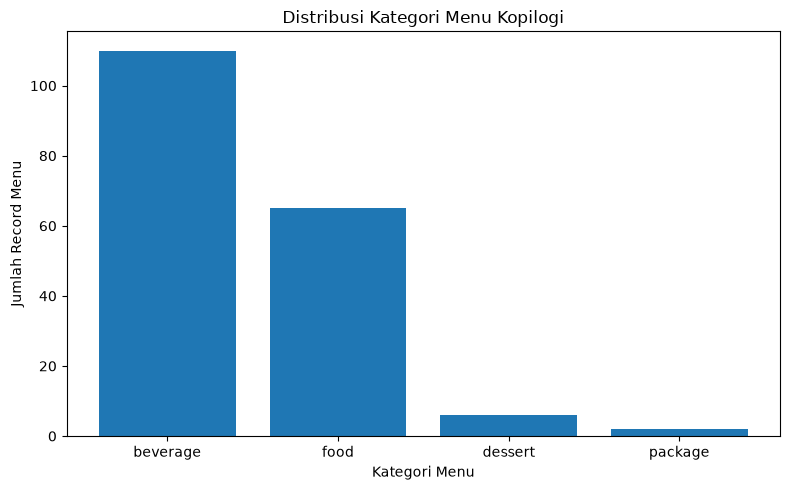

In [3]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_counts["category"],
    category_counts["jumlah_menu"]
)

plt.title("Distribusi Kategori Menu Kopilogi")
plt.xlabel("Kategori Menu")
plt.ylabel("Jumlah Record Menu")

plt.tight_layout()
plt.show()

In [4]:
price_summary = df["price"].describe()

print("=== STATISTIK HARGA MENU ===")
display(price_summary)

=== STATISTIK HARGA MENU ===


count       183.000000
mean      23964.480874
std       14083.935812
min       10000.000000
25%       17500.000000
50%       22500.000000
75%       26500.000000
max      130500.000000
Name: price, dtype: float64

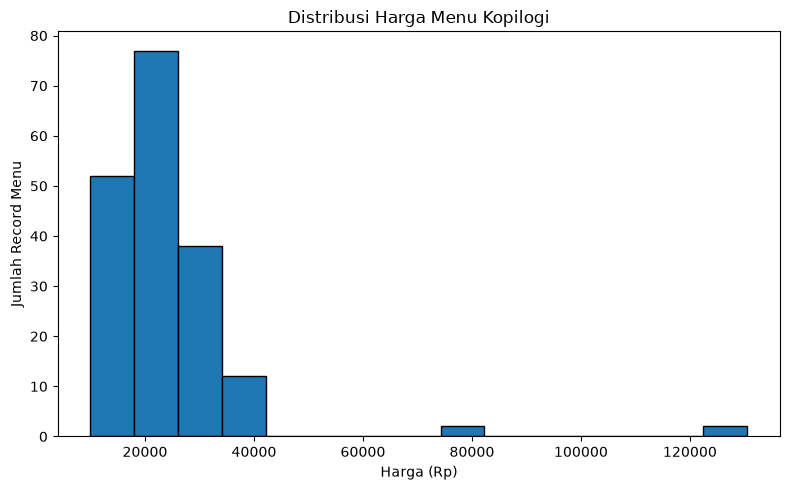

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["price"].dropna(),
    bins=15,
    edgecolor="black"
)

plt.title("Distribusi Harga Menu Kopilogi")
plt.xlabel("Harga (Rp)")
plt.ylabel("Jumlah Record Menu")

plt.tight_layout()
plt.show()

In [6]:
print("=== STATISTIK HARGA PER KATEGORI ===")

price_by_category = (
    df.groupby("category_group")["price"]
    .agg(
        jumlah_menu="count",
        harga_minimum="min",
        harga_median="median",
        harga_rata_rata="mean",
        harga_maksimum="max"
    )
    .round(2)
    .sort_values("harga_median")
)

display(price_by_category)

=== STATISTIK HARGA PER KATEGORI ===


,jumlah_menu,harga_minimum,harga_median,harga_rata_rata,harga_maksimum
category_group,,,,,
package,2,15000,17500.0,17500.00,20000
dessert,6,18500,20500.0,21500.00,25500
beverage,110,10000,21500.0,24009.09,130500
food,65,12500,23500.0,24315.38,40500


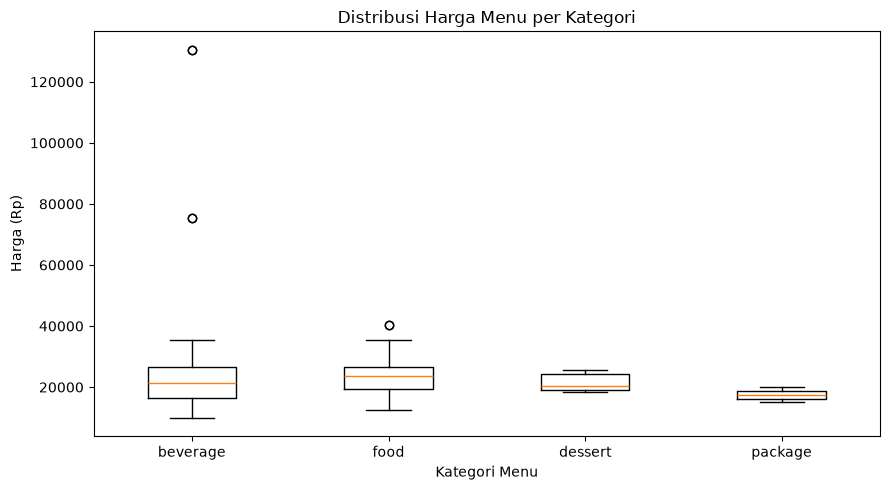

In [7]:
import matplotlib.pyplot as plt

categories = ["beverage", "food", "dessert", "package"]

price_data = [
    df.loc[
        df["category_group"] == category,
        "price"
    ].dropna()
    for category in categories
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    price_data,
    tick_labels=categories
)

plt.title("Distribusi Harga Menu per Kategori")
plt.xlabel("Kategori Menu")
plt.ylabel("Harga (Rp)")

plt.tight_layout()
plt.show()

In [8]:
print("=== ANALISIS MENU PER CABANG ===")

branch_summary = (
    df.groupby("branch_id")
    .agg(
        jumlah_menu=("menu_id", "count"),
        jumlah_kategori=("category_group", "nunique"),
        harga_minimum=("price", "min"),
        harga_median=("price", "median"),
        harga_rata_rata=("price", "mean"),
        harga_maksimum=("price", "max")
    )
    .round(2)
)

display(branch_summary)

=== ANALISIS MENU PER CABANG ===


,jumlah_menu,jumlah_kategori,harga_minimum,harga_median,harga_rata_rata,harga_maksimum
branch_id,,,,,,
BR001,56,3,18500,25500.0,28678.57,130500
BR002,71,3,10000,16500.0,16528.17,25500
BR003,56,3,18500,25500.0,28678.57,130500


In [9]:
print("=== ANALISIS PRODUK UNIK ===")

# Normalisasi nama untuk keperluan penghitungan
df["menu_name_normalized"] = (
    df["menu_name"]
    .astype("string")
    .str.strip()
    .str.lower()
)

jumlah_record = len(df)

jumlah_nama_unik = (
    df["menu_name_normalized"].nunique()
)

jumlah_kombinasi_unik = (
    df[["menu_name_normalized", "category"]]
    .drop_duplicates()
    .shape[0]
)

print("Total record katalog:", jumlah_record)
print("Jumlah nama menu unik:", jumlah_nama_unik)
print(
    "Jumlah kombinasi nama dan kategori unik:",
    jumlah_kombinasi_unik
)

=== ANALISIS PRODUK UNIK ===
Total record katalog: 183
Jumlah nama menu unik: 114
Jumlah kombinasi nama dan kategori unik: 127


In [10]:
from pathlib import Path

reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Menyimpan distribusi kategori
category_counts.to_csv(
    reports_dir / "eda_category_distribution.csv",
    index=False
)

# Menyimpan statistik harga per kategori
price_by_category.to_csv(
    reports_dir / "eda_price_by_category.csv"
)

# Menyimpan ringkasan per cabang
branch_summary.to_csv(
    reports_dir / "eda_branch_summary.csv"
)

print("Seluruh tabel hasil EDA berhasil disimpan.")

Seluruh tabel hasil EDA berhasil disimpan.


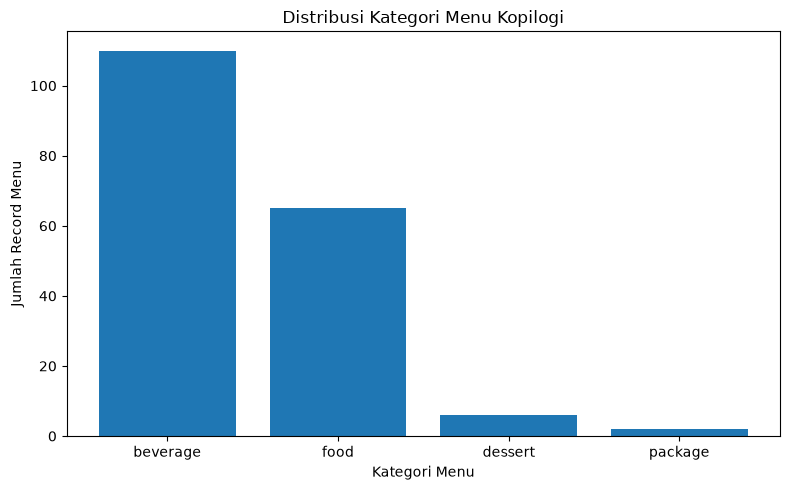

In [11]:
import matplotlib.pyplot as plt

# Grafik distribusi kategori
plt.figure(figsize=(8, 5))
plt.bar(
    category_counts["category"],
    category_counts["jumlah_menu"]
)

plt.title("Distribusi Kategori Menu Kopilogi")
plt.xlabel("Kategori Menu")
plt.ylabel("Jumlah Record Menu")
plt.tight_layout()

plt.savefig(
    reports_dir / "eda_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Analisis Karakteristik Katalog Menu Kopilogi

Berdasarkan hasil pengolahan terhadap 183 record katalog menu Kopilogi, kategori beverage memiliki jumlah record terbanyak, yaitu 110 record (60,11%), diikuti food sebanyak 65 record (35,52%), dessert sebanyak 6 record (3,28%), dan package sebanyak 2 record (1,09%).

Analisis harga menunjukkan bahwa kategori food memiliki median harga sebesar Rp23.500, sedangkan beverage sebesar Rp21.500. Pada kategori beverage, terdapat beberapa produk botolan berukuran besar dengan harga lebih tinggi dibandingkan sebagian besar menu lainnya, sehingga nilai rata-rata harga perlu diinterpretasikan bersama median.

Berdasarkan pengelompokan cabang, BR002 memiliki 71 record menu dengan median harga Rp16.500, sedangkan BR001 dan BR003 masing-masing memiliki 56 record dengan median harga Rp25.500. Meskipun demikian, hasil pemeriksaan menunjukkan bahwa katalog BR001 dan BR003 identik berdasarkan nama, kategori, dan harga, sehingga kesesuaian informasi kedua cabang masih memerlukan konfirmasi.

Hasil analisis ini menggambarkan karakteristik katalog menu yang berhasil dikumpulkan dan belum dapat digunakan untuk menyimpulkan volume penjualan, preferensi pelanggan, atau profitabilitas masing-masing cabang.